# Hospital Data Cleaning & Quality Analysis

**Project type:** Data Cleaning · Data Quality · Exploratory Data Analysis  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Project overview
This notebook demonstrates a reproducible workflow for inspecting, cleaning, validating, and exploring a hospital dataset. The original source file is kept separate from processed outputs.

## 1. Setup and load data

Place the source CSV at `data/raw/synthetic_hospital_dataset.csv`. The notebook also checks the common `/mnt/data/` location used in the original working environment.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

candidate_paths = [
    PROJECT_ROOT / "data" / "raw" / "synthetic_hospital_dataset.csv",
    Path("/mnt/data/synthetic_hospital_dataset.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Add synthetic_hospital_dataset.csv to data/raw/ "
        "or update DATA_PATH to your local CSV path."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Loaded: {DATA_PATH}")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Loaded: d:\Data Engineer\hospital-data-cleaning\data\raw\synthetic_hospital_dataset.csv
Rows: 1,212 | Columns: 17


,patient_id,first_name,last_name,age,gender,blood_type,admission_date,discharge_date,diagnosis,department,doctor_name,room_number,bill_amount,insurance_provider,phone_number,email,city
0,P00001,Omar,Hassan,2,Male,AB+,2025-02-05,2025-02-17,Asthma,Oncology,Dr. Nada Fathy,609,4774.01,Self-Pay,+208145326358,farah.ibrahim1@example.com,New Valley
1,P00002,Farah,Hassan,55,Female,A-,2023-08-04,2023-08-15,Migraine,Oncology,Dr. Sara Hassan,501,4448.8,Public Health Insurance,+205699205239,jana.hassan2@example.com,Alexandria
2,P00003,Salma,Nabil,54,Female,AB-,2025-02-19,2025-02-28,Diabetes,Oncology,Dr. Omar Mostafa,782,3892.37,MedNet,+207622333791,jana.adel3@example.com,Luxor
3,P00004,Jana,Nabil,64,Female,O-,2023-01-26,2023-01-27,Migraine,General Surgery,Dr. Nada Fathy,417,4073.95,Self-Pay,+202621821439,malak.samir4@example.com,New Valley
4,P00005,Laila,Nabil,56,Female,B+,2024-01-20,2024-01-22,Fracture,Radiology,Dr. Sara Hassan,195,6032.14,CarePlus,+203524849950,nour.mahmoud5@example.com,Assiut


## 2. Initial data inspection

Review the schema, sample records, duplicate rows, and missingness before changing any values.

In [4]:
display(df.head(10))
display(df.sample(min(5, len(df)), random_state=42))
df.info()
display(df.describe(include="all").T)

,patient_id,first_name,last_name,age,gender,blood_type,admission_date,discharge_date,diagnosis,department,doctor_name,room_number,bill_amount,insurance_provider,phone_number,email,city
0,P00001,Omar,Hassan,2,Male,AB+,2025-02-05,2025-02-17,Asthma,Oncology,Dr. Nada Fathy,609,4774.01,Self-Pay,+208145326358,farah.ibrahim1@example.com,New Valley
1,P00002,Farah,Hassan,55,Female,A-,2023-08-04,2023-08-15,Migraine,Oncology,Dr. Sara Hassan,501,4448.8,Public Health Insurance,+205699205239,jana.hassan2@example.com,Alexandria
2,P00003,Salma,Nabil,54,Female,AB-,2025-02-19,2025-02-28,Diabetes,Oncology,Dr. Omar Mostafa,782,3892.37,MedNet,+207622333791,jana.adel3@example.com,Luxor
3,P00004,Jana,Nabil,64,Female,O-,2023-01-26,2023-01-27,Migraine,General Surgery,Dr. Nada Fathy,417,4073.95,Self-Pay,+202621821439,malak.samir4@example.com,New Valley
4,P00005,Laila,Nabil,56,Female,B+,2024-01-20,2024-01-22,Fracture,Radiology,Dr. Sara Hassan,195,6032.14,CarePlus,+203524849950,nour.mahmoud5@example.com,Assiut
5,P00006,Jana,Ibrahim,1,Female,O-,2023-06-13,2023-06-27,Migraine,Radiology,Dr. Youssef Samir,343,3520.8,NaN,+206363073401,unknown,Qena
6,P00007,Farah,Mahmoud,58,female,A-,2025-03-31,2025-04-07,Fracture,Dermatology,Dr. Ahmed Ali,716,3478.18,Self-Pay,+206630642750,mostafa.sayed7@example.com,Giza
7,P00008,Omar,Mostafa,NaN,female,B-,2023-05-09,2023-05-23,Fracture,ICU,Dr. Youssef Samir,512,7522.64,Self-Pay,+201838492924,nour.mohamed8@example.com,Minya
8,P00009,Malak,Samir,25,Male,AB-,2024-10-18,2024-11-02,Diabetes,Neurology,Dr. Youssef Samir,792,2921.92,Public Health Insurance,+206687907035,adam.gamal9@example.com,Luxor
9,P00010,Adam,Khaled,24,Male,AB-,2023-02-22,2023-03-01,Pneumonia,Oncology,Dr. Ahmed Ali,315,not available,MedNet,+207497558755,youssef.samir10@example.com,Qena


,patient_id,first_name,last_name,age,gender,blood_type,admission_date,discharge_date,diagnosis,department,doctor_name,room_number,bill_amount,insurance_provider,phone_number,email,city
801,P00802,Salma,Ibrahim,80,Female,O+,2023-09-23,2023-10-04,Migraine,Pediatrics,Dr. Mariam Adel,389,1285.41,NaN,+204304732209,karim.fathy802@example.com,Qena
677,P00678,Nour,Khaled,11,Male,O-,2023-08-26,2023-09-04,Fracture,Gynecology,Dr. Sara Hassan,522,2289.46,Private Insurance,+208324506744,NaN,Qena
43,P00044,Mostafa,Mohamed,83,,AB-,2024-05-19,2024-05-29,Appendicitis,Neurology,Dr. Youssef Samir,728,2772.96,CarePlus,+203792477182,nour.mostafa44@example.com,Alexandria
990,P00991,Malak,Tarek,4,Female,A-,2024-01-25,2024-01-26,Pneumonia,Neurology,Dr. Omar Mostafa,690,4546.38,Public Health Insurance,+203439152137,malak.mostafa991@example.com,Sohag
70,P00071,Jana,Khaled,35,Female,A+,2023-08-09,2023-08-21,Appendicitis,Psychiatry,Dr. Omar Mostafa,275,5245.33,NaN,+201712632528,amr.mahmoud71@example.com,Alexandria


<class 'pandas.DataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   patient_id          1212 non-null   str  
 1   first_name          1212 non-null   str  
 2   last_name           1212 non-null   str  
 3   age                 1179 non-null   str  
 4   gender              1195 non-null   str  
 5   blood_type          1199 non-null   str  
 6   admission_date      1212 non-null   str  
 7   discharge_date      1212 non-null   str  
 8   diagnosis           1200 non-null   str  
 9   department          1195 non-null   str  
 10  doctor_name         1200 non-null   str  
 11  room_number         1192 non-null   str  
 12  bill_amount         1190 non-null   str  
 13  insurance_provider  994 non-null    str  
 14  phone_number        1199 non-null   str  
 15  email               1187 non-null   str  
 16  city                1197 non-null   str  
dtypes: str

,count,unique,top,freq
patient_id,1212,1200,P00047,2
first_name,1212,18,Amr,82
last_name,1212,14,Adel,108
age,1179,101,61,22
gender,1195,9,Male,584
blood_type,1199,11,A-,161
admission_date,1212,710,2024-04-21,7
discharge_date,1212,712,2025-06-07,6
diagnosis,1200,13,Dermatitis,127
department,1195,34,Cardiology,111


In [5]:
initial_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(initial_summary.sort_values("missing_pct", ascending=False))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

,dtype,missing_count,missing_pct,unique_values
insurance_provider,str,218,17.99,8
age,str,33,2.72,101
email,str,25,2.06,1137
bill_amount,str,22,1.82,1153
room_number,str,20,1.65,575
department,str,17,1.40,34
gender,str,17,1.40,9
city,str,15,1.24,21
phone_number,str,13,1.07,1173
blood_type,str,13,1.07,11


Exact duplicate rows: 12


## 3. Normalize missing-value markers and whitespace

Text markers such as `N/A`, `NULL`, `unknown`, and `-` are converted to missing values. Whether a marker should mean missing is context-dependent, so review this list for each real dataset.

In [6]:
MISSING_MARKERS = {"n/a", "nan", "null", "unknown", "-", ""}

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()
    normalized = df[col].str.casefold()
    df.loc[normalized.isin(MISSING_MARKERS), col] = pd.NA

display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

,missing_count
insurance_provider,238
age,53
email,48
bill_amount,44
room_number,36
city,30
gender,30
department,30
phone_number,30
doctor_name,25


## 4. Detect and handle duplicate records

Exact duplicates are removed first. Potential logical duplicates are flagged using patient attributes while excluding `patient_id`. Similar attributes do not always prove two rows refer to the same person, so inspect flagged records before dropping them in production.

In [7]:
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

logical_key = [
    c for c in [
        "first_name", "last_name", "age", "gender", "blood_type",
        "admission_date", "discharge_date", "diagnosis", "department",
        "doctor_name", "room_number", "bill_amount",
        "insurance_provider", "phone_number", "email", "city"
    ] if c in df.columns
]

if logical_key:
    potential_duplicates = df[df.duplicated(subset=logical_key, keep=False)].copy()
else:
    potential_duplicates = pd.DataFrame()

print(f"Exact duplicate rows removed: {exact_duplicates:,}")
print(f"Rows flagged as potential logical duplicates: {len(potential_duplicates):,}")
display(potential_duplicates.head(10))

Exact duplicate rows removed: 12
Rows flagged as potential logical duplicates: 0


,patient_id,first_name,last_name,age,gender,blood_type,admission_date,discharge_date,diagnosis,department,doctor_name,room_number,bill_amount,insurance_provider,phone_number,email,city


## 5. Standardize categorical and text fields

Normalize casing and whitespace without silently mapping unknown categories to missing values. Unmapped values are reported for review.

In [8]:
for col in [
    "first_name", "last_name", "diagnosis",
    "insurance_provider", "doctor_name", "city", "department", "gender"
]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

if "city" in df.columns:
    df["city"] = df["city"].str.title()

if "department" in df.columns:
    department_mapper = {
        "cardiology": "Cardiology", "neurology": "Neurology",
        "orthopedics": "Orthopedics", "pediatrics": "Pediatrics",
        "oncology": "Oncology", "emergency": "Emergency",
        "radiology": "Radiology", "general surgery": "General Surgery",
        "icu": "ICU", "dermatology": "Dermatology",
        "gynecology": "Gynecology", "psychiatry": "Psychiatry"
    }
    department_normalized = df["department"].str.casefold()
    mapped_department = department_normalized.map(department_mapper)
    unknown_department_mask = df["department"].notna() & mapped_department.isna()
    unknown_departments = sorted(df.loc[unknown_department_mask, "department"].dropna().unique().tolist())
    df.loc[~unknown_department_mask, "department"] = mapped_department.loc[~unknown_department_mask]

if "gender" in df.columns:
    gender_mapper = {
        "male": "Male", "m": "Male", "man": "Male",
        "female": "Female", "f": "Female", "woman": "Female"
    }
    gender_normalized = df["gender"].str.casefold()
    mapped_gender = gender_normalized.map(gender_mapper)
    unknown_gender_mask = df["gender"].notna() & mapped_gender.isna()
    unknown_genders = sorted(df.loc[unknown_gender_mask, "gender"].dropna().unique().tolist())
    df.loc[~unknown_gender_mask, "gender"] = mapped_gender.loc[~unknown_gender_mask]

if "blood_type" in df.columns:
    df["blood_type"] = df["blood_type"].str.upper()

print("Unmapped department values:", unknown_departments if "department" in df.columns else [])
print("Unmapped gender values:", unknown_genders if "gender" in df.columns else [])

Unmapped department values: []
Unmapped gender values: []


## 6. Validate and convert numeric fields

Convert values explicitly and flag invalid ranges. Age and room-number thresholds should be confirmed against the dataset's business rules before production use. Missing values are not imputed automatically here; the quality report preserves visibility into them.

In [9]:
if "age" in df.columns:
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    invalid_age_mask = df["age"].notna() & ~df["age"].between(0, 120)
    print(f"Age values outside 0–120: {int(invalid_age_mask.sum()):,}")
    df.loc[invalid_age_mask, "age"] = np.nan

if "bill_amount" in df.columns:
    bill_text = (
        df["bill_amount"].astype("string")
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    df["bill_amount"] = pd.to_numeric(bill_text, errors="coerce")
    negative_bill_mask = df["bill_amount"] < 0
    print(f"Negative bill amounts: {int(negative_bill_mask.sum()):,}")
    df.loc[negative_bill_mask, "bill_amount"] = np.nan

if "room_number" in df.columns:
    df["room_number"] = pd.to_numeric(df["room_number"], errors="coerce")
    # Review this rule against the hospital's actual room-number convention.
    invalid_room_mask = df["room_number"].notna() & ~df["room_number"].between(100, 799)
    print(f"Room numbers outside configured range 100–799: {int(invalid_room_mask.sum()):,}")
    df.loc[invalid_room_mask, "room_number"] = np.nan

display(df.select_dtypes(include="number").describe().T)

Age values outside 0–120: 8
Negative bill amounts: 3
Room numbers outside configured range 100–799: 6


,count,mean,std,min,25%,50%,75%,max
age,1136.0,47.144366,27.253037,1.0,23.0,47.0,71.0,95.0
room_number,1157.0,445.847018,201.817511,100.0,271.0,447.0,621.0,798.0
bill_amount,1151.0,3515.413579,1437.263531,431.81,2476.195,3395.15,4384.425,10667.66


## 7. Validate email addresses and dates

Email validation here is a practical format check, not proof that an address exists. Date rules flag missing or reversed dates; invalid records are not silently discarded.

In [10]:
if "email" in df.columns:
    email_pattern = r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$"
    valid_email = df["email"].str.match(email_pattern, na=False)
    invalid_email_mask = df["email"].notna() & ~valid_email
    print(f"Non-empty email values failing format check: {int(invalid_email_mask.sum()):,}")
    df.loc[invalid_email_mask, "email"] = pd.NA

date_columns = [c for c in ["admission_date", "discharge_date"] if c in df.columns]
for col in date_columns:
    df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

if {"admission_date", "discharge_date"}.issubset(df.columns):
    missing_date_mask = df["admission_date"].isna() | df["discharge_date"].isna()
    reversed_date_mask = (
        df["admission_date"].notna()
        & df["discharge_date"].notna()
        & (df["discharge_date"] < df["admission_date"])
    )
    print(f"Rows with missing/unparseable admission or discharge date: {int(missing_date_mask.sum()):,}")
    print(f"Rows with discharge before admission: {int(reversed_date_mask.sum()):,}")
    df.loc[reversed_date_mask, "discharge_date"] = pd.NaT

Non-empty email values failing format check: 22
Rows with missing/unparseable admission or discharge date: 10
Rows with discharge before admission: 361


## 8. Missing-value strategy

Avoid filling every missing value with a median by default. For this portfolio project, report the remaining missingness first; choose imputation rules based on the use case and document any assumptions.

In [11]:
quality_after_cleaning = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(quality_after_cleaning.sort_values("missing_pct", ascending=False))

,dtype,missing_count,missing_pct,unique_values
discharge_date,datetime64[us],366,30.50,535
insurance_provider,string,235,19.58,5
email,string,70,5.83,1130
age,Int64,64,5.33,95
bill_amount,Float64,49,4.08,1148
room_number,Int64,43,3.58,569
city,string,30,2.50,9
gender,string,30,2.50,2
phone_number,string,30,2.50,1170
department,string,30,2.50,12


## 9. Feature engineering

Calculate length of stay and bill per day only when both dates and the bill amount are valid. A zero-day stay is treated as one billing day for this derived metric; confirm this assumption for the actual business context.

In [12]:
if {"admission_date", "discharge_date"}.issubset(df.columns):
    df["length_of_stay_days"] = (df["discharge_date"] - df["admission_date"]).dt.days
    df.loc[df["length_of_stay_days"] < 0, "length_of_stay_days"] = np.nan

if {"bill_amount", "length_of_stay_days"}.issubset(df.columns):
    billing_days = df["length_of_stay_days"].clip(lower=1)
    df["bill_per_day"] = df["bill_amount"] / billing_days

display(df.head())

,patient_id,first_name,last_name,age,gender,blood_type,admission_date,discharge_date,diagnosis,department,doctor_name,room_number,bill_amount,insurance_provider,phone_number,email,city,length_of_stay_days,bill_per_day
0,P00001,Omar,Hassan,2,Male,AB+,2025-05-02,NaT,Asthma,Oncology,Dr. Nada Fathy,609,4774.01,Self-Pay,+208145326358,farah.ibrahim1@example.com,New Valley,NaN,<NA>
1,P00002,Farah,Hassan,55,Female,A-,2023-04-08,2023-08-15,Migraine,Oncology,Dr. Sara Hassan,501,4448.8,Public Health Insurance,+205699205239,jana.hassan2@example.com,Alexandria,129.0,34.486822
2,P00003,Salma,Nabil,54,Female,AB-,2025-02-19,2025-02-28,Diabetes,Oncology,Dr. Omar Mostafa,782,3892.37,MedNet,+207622333791,jana.adel3@example.com,Luxor,9.0,432.485556
3,P00004,Jana,Nabil,64,Female,O-,2023-01-26,2023-01-27,Migraine,General Surgery,Dr. Nada Fathy,417,4073.95,Self-Pay,+202621821439,malak.samir4@example.com,New Valley,1.0,4073.95
4,P00005,Laila,Nabil,56,Female,B+,2024-01-20,2024-01-22,Fracture,Radiology,Dr. Sara Hassan,195,6032.14,CarePlus,+203524849950,nour.mahmoud5@example.com,Assiut,2.0,3016.07


## 10. Before-and-after quality summary

The source row count, exact duplicate count, and missingness metrics provide a transparent audit trail. Logical duplicate candidates are reported rather than automatically deleted.

In [13]:
summary = pd.DataFrame([
    {"metric": "rows_before_cleaning", "value": len(df_raw)},
    {"metric": "columns_before_cleaning", "value": df_raw.shape[1]},
    {"metric": "exact_duplicate_rows_before_cleaning", "value": int(df_raw.duplicated().sum())},
    {"metric": "rows_after_cleaning", "value": len(df)},
    {"metric": "columns_after_cleaning", "value": df.shape[1]},
    {"metric": "missing_cells_before_cleaning", "value": int(df_raw.isna().sum().sum())},
    {"metric": "missing_cells_after_cleaning", "value": int(df.isna().sum().sum())},
])
display(summary)

,metric,value
0,rows_before_cleaning,1212
1,columns_before_cleaning,17
2,exact_duplicate_rows_before_cleaning,12
3,rows_after_cleaning,1200
4,columns_after_cleaning,19
5,missing_cells_before_cleaning,417
6,missing_cells_after_cleaning,1800


## 11. Exploratory data analysis

These charts are descriptive and should not be interpreted as clinical conclusions.

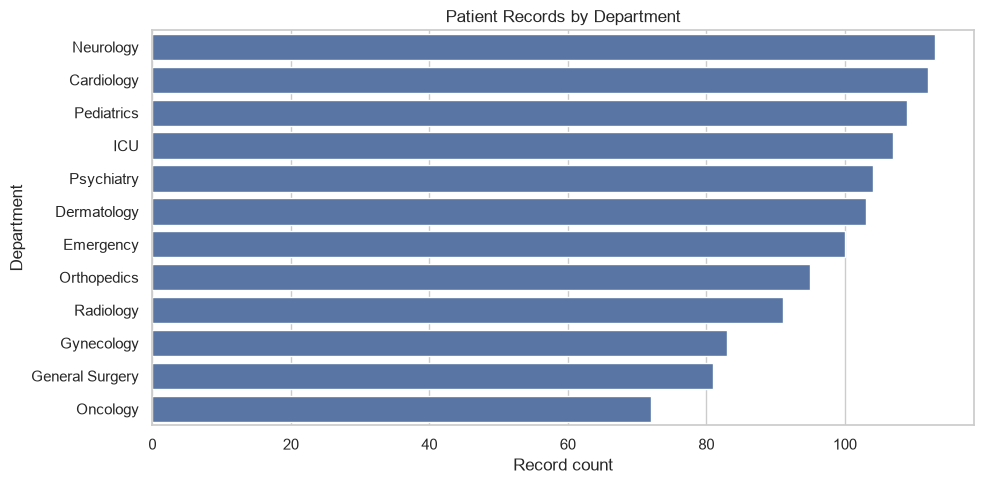

In [14]:
if "department" in df.columns:
    plt.figure(figsize=(10, 5))
    order = df["department"].value_counts().index
    sns.countplot(data=df, y="department", order=order)
    plt.title("Patient Records by Department")
    plt.xlabel("Record count")
    plt.ylabel("Department")
    plt.tight_layout()
    plt.show()

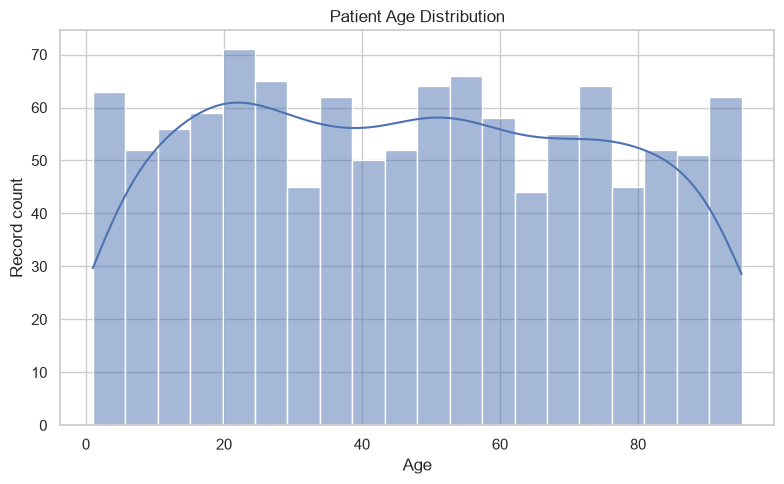

In [15]:
if "age" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x="age", bins=20, kde=True)
    plt.title("Patient Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Record count")
    plt.tight_layout()
    plt.show()

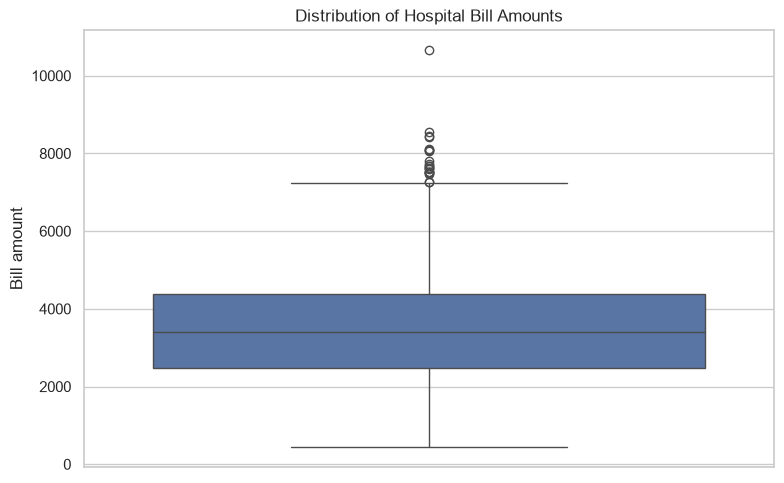

In [16]:
if "bill_amount" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, y="bill_amount")
    plt.title("Distribution of Hospital Bill Amounts")
    plt.ylabel("Bill amount")
    plt.tight_layout()
    plt.show()

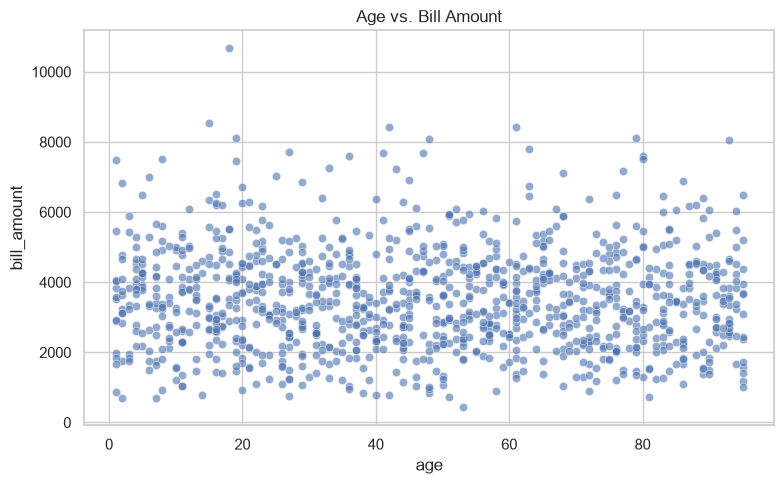

In [17]:
if {"age", "bill_amount"}.issubset(df.columns):
    plot_data = df[["age", "bill_amount"]].dropna()
    if not plot_data.empty:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=plot_data.sample(min(5000, len(plot_data)), random_state=42),
                        x="age", y="bill_amount", alpha=0.6)
        plt.title("Age vs. Bill Amount")
        plt.tight_layout()
        plt.show()

## 12. Export cleaned data and quality report

Processed outputs are written to `data/processed/`. Do not commit sensitive source or processed data to a public repository.

In [18]:
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cleaned_path = OUTPUT_DIR / "hospital_cleaned.csv"
quality_path = OUTPUT_DIR / "data_quality_report.csv"

df.to_csv(cleaned_path, index=False)
quality_after_cleaning.to_csv(quality_path, index=True)

print(f"Cleaned dataset saved to: {cleaned_path}")
print(f"Quality report saved to: {quality_path}")

Cleaned dataset saved to: d:\Data Engineer\hospital-data-cleaning\data\processed\hospital_cleaned.csv
Quality report saved to: d:\Data Engineer\hospital-data-cleaning\data\processed\data_quality_report.csv
